# Federated Radar Position Recognition (mmWave MIMO Radar)
**Gizlilik Odaklı İnsan-Robot Ortak Çalışma Alanında Konum Tanıma Sistemi**

Bu çalışma defteri, Texas Instruments **AWR1842 (77 GHz, 2Tx-4Rx)** mmWave MIMO radarlarından elde edilen `(256, 63)` boyutlu Range-Azimuth (Menzil-Açı) ısı haritaları üzerinde **Federated Learning (FedAvg & FedProx)** ve **Merkezi (Centralized)** derin öğrenme modellerini eğitir ve karşılaştırır.

### Giderilen Hatalar ve Geliştirmeler
1. **uint8 Etiket Taşması (Underflow) Düzeltmesi**: Orijinal koddaki `labels.flatten() - 1` işlemi `0` etiketini `255` değerine taşırıyordu. Etiketler doğrudan `0..9` (`int64`) olarak yüklendi.
2. **3 Günün Tamamının (`day0`, `day1`, `day2`) Entegrasyonu**: 9 istemci x 3 gün = **9.000 eğitim örneği** ve **3.500 global test örneği** tamamıyla sisteme dahil edildi.
3. **GroupNorm Tabanlı 2D CNN (`RadarPositionCNN`)**: Federated Learning sırasında BatchNorm istatistiklerinin istemciler arasında sapmasını (client drift) önlemek için `GroupNorm` mimarisi kullanıldı.
4. **IID vs. Non-IID (Dirichlet $\alpha=0.3$) ve FedAvg vs. FedProx ($\mu=0.05$) Analizi**: Veri heterojenliği altında algoritmaların yakınsama davranışı karşılaştırıldı.
5. **TI AWR1842 Gerçek Zamanlı TLV Köprüsü**: Raspberry Pi / Seri Port üzerinden gelen ham TLV Azimuth Static Heatmap paketlerini `(256, 63)` matrisine dönüştürüp ~3.7 ms içinde konum tahmini yapan köprü entegre edildi.

In [1]:
import os
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.dataset import DEFAULT_RADAR_DATA_DIR, load_all_days_dataset, create_non_iid_partition, get_client_class_distribution, to_dataloader
from src.models import RadarPositionCNN
from src.fl_engine import run_centralized_training, run_federated_training, evaluate_model
from src.awr1842_bridge import parse_awr1842_config, raw_tlv_azimuth_to_heatmap, predict_radar_frame

print(f"PyTorch Sürümü: {torch.__version__}")
radar_cfg = parse_awr1842_config()
print(f"AWR1842 Radar Parametreleri: {radar_cfg}")

PyTorch Sürümü: 2.15.0+cpu
AWR1842 Radar Parametreleri: {'numTxAnt': 2, 'numRxAnt': 4, 'numVirtualAnt': 8, 'numRangeBins': 256, 'numAngleBins': 63, 'numDopplerBins': 16, 'rangeResolutionMeters': 0.0436, 'rangeIdxToMeters': 0.0436, 'dopplerResolutionMps': 0.1252, 'maxRangeMeters': 10.05, 'maxVelocityMps': 1.0}


Toplam Eğitim Verisi (9 İstemci x 3 Gün): 9000 örnek
Toplam Global Test Verisi: 3500 örnek (day0: 1500, day1: 1000, day2: 1000)


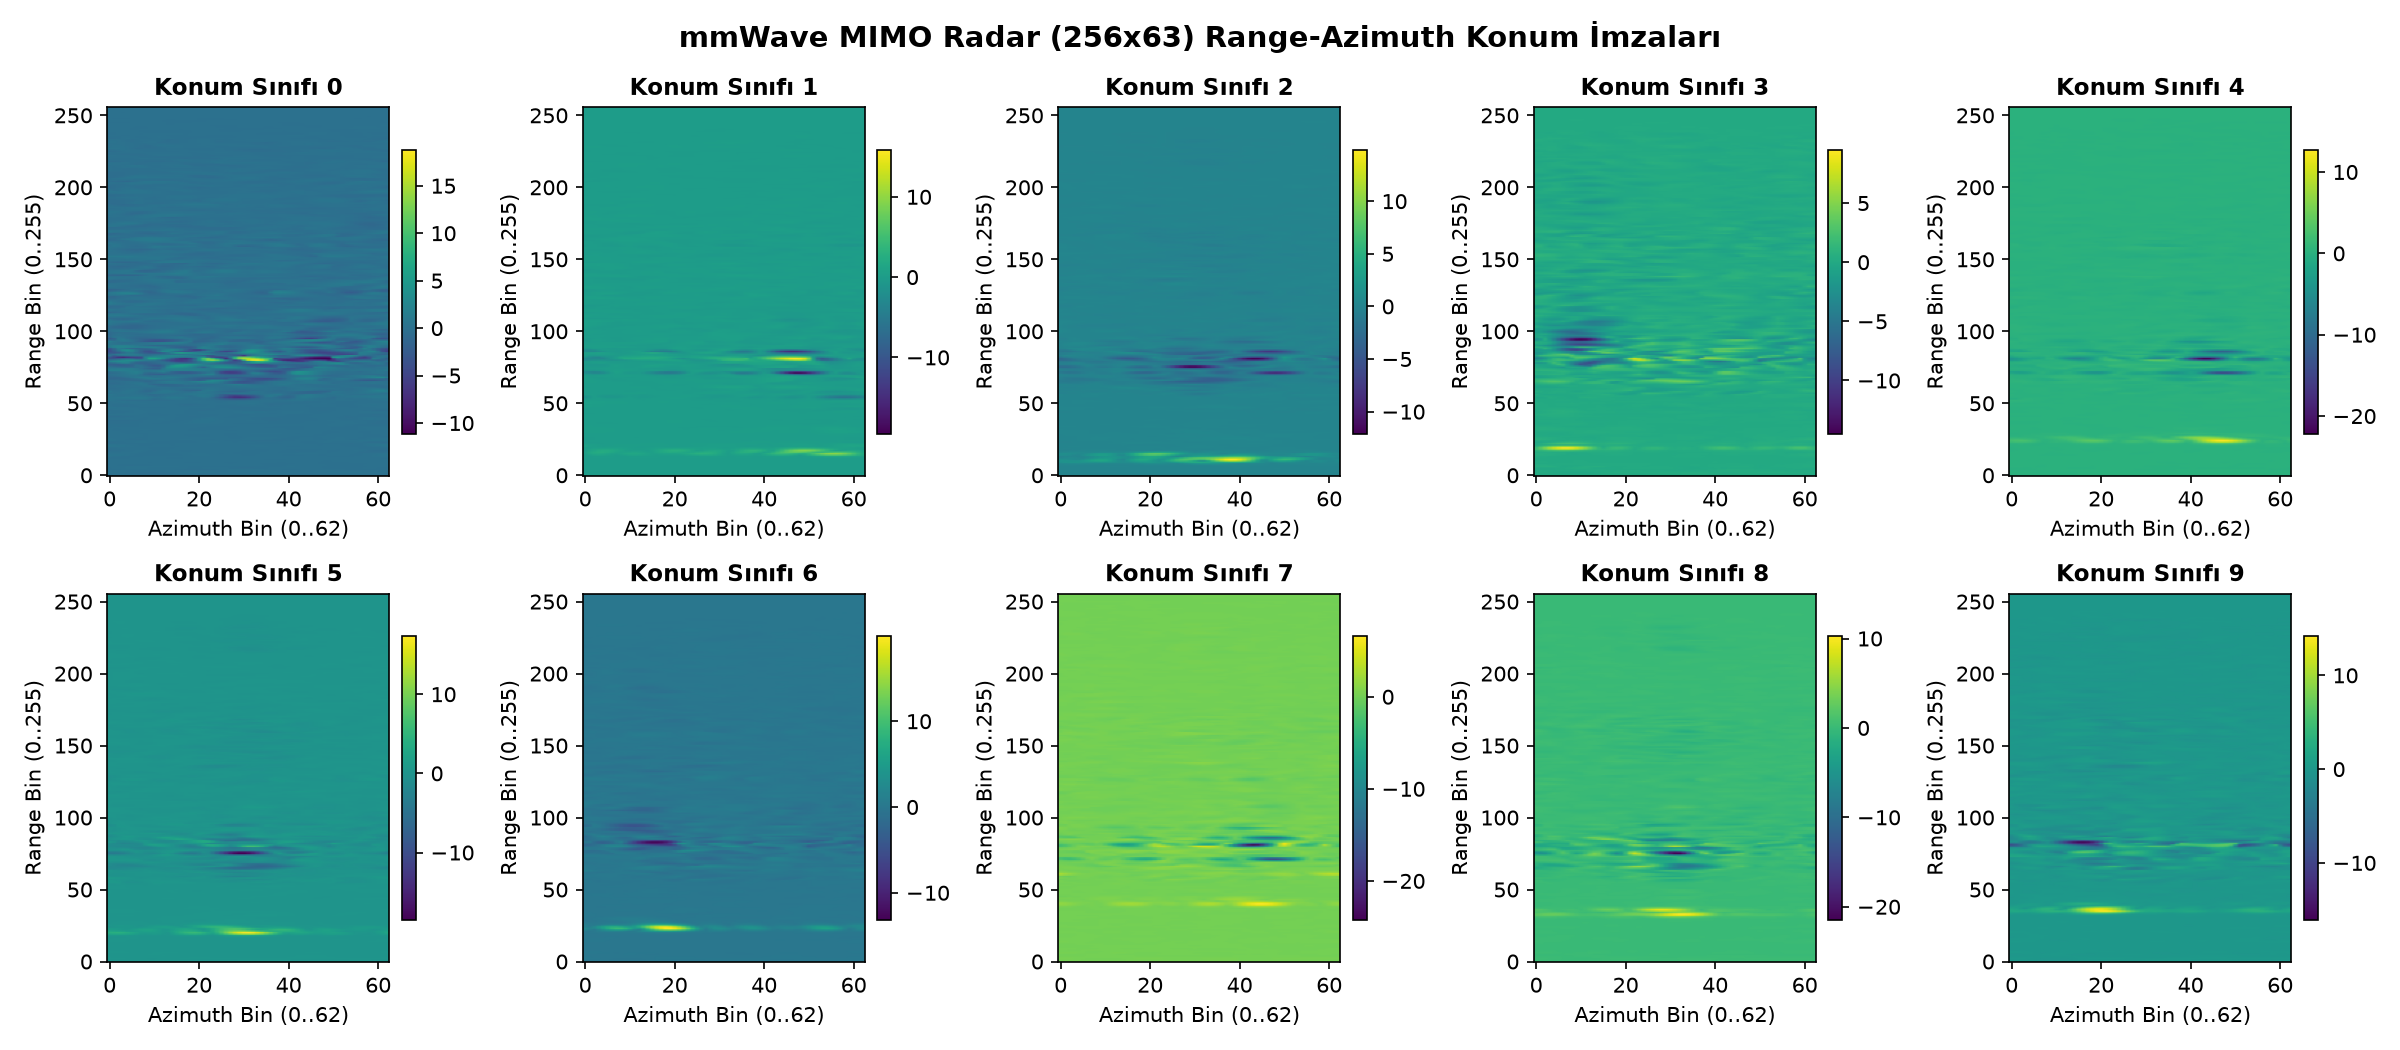

In [2]:
# 1. Veri Setinin Yüklenmesi ve 10 Konum Sınıfının Range-Azimuth İmzaları
clients_iid, day_tests, (global_test_x, global_test_y) = load_all_days_dataset()
print(f"Toplam Eğitim Verisi (9 İstemci x 3 Gün): {sum(len(v[1]) for v in clients_iid.values())} örnek")
print(f"Toplam Global Test Verisi: {len(global_test_y)} örnek (day0: {len(day_tests['day0'][1])}, day1: {len(day_tests['day1'][1])}, day2: {len(day_tests['day2'][1])})")
display(Image(filename="results/radar_range_azimuth_samples.png"))

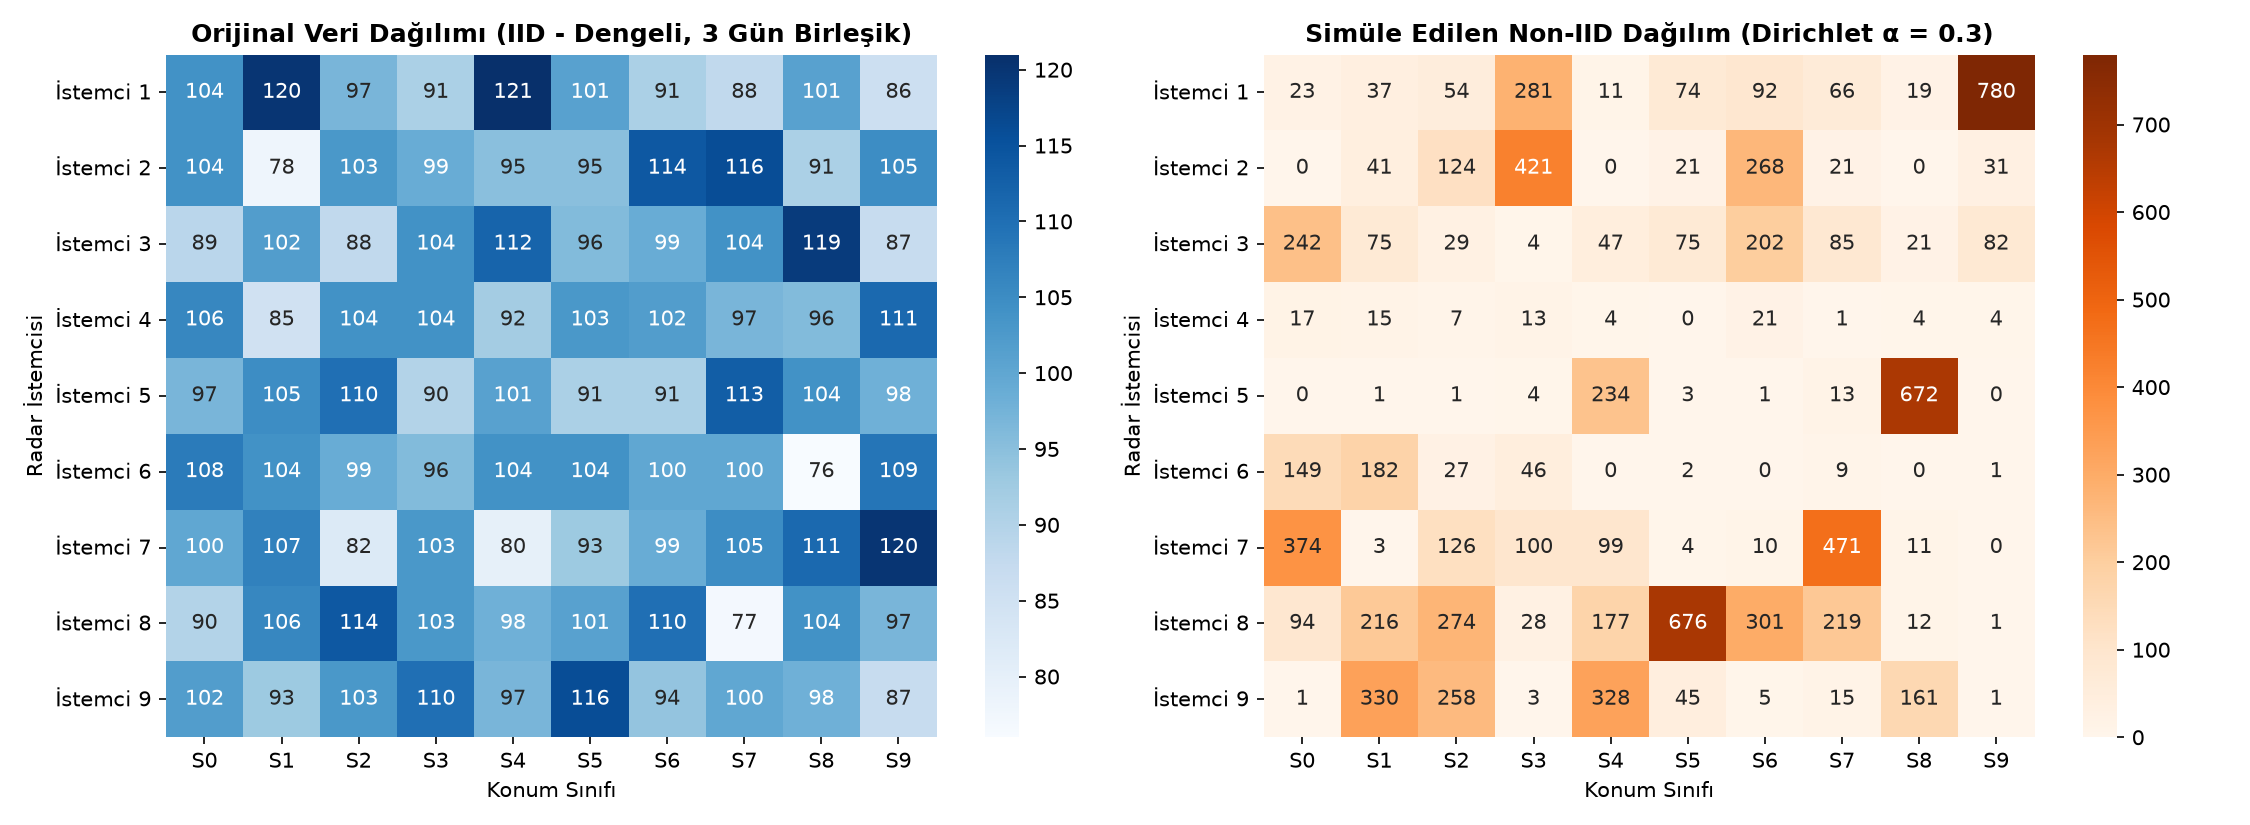

In [3]:
# 2. İstemci Veri Dağılımı: Orijinal (IID) vs. Simüle Edilen Non-IID (Dirichlet alpha=0.3)
clients_non_iid = create_non_iid_partition(clients_iid, alpha=0.3, seed=42)
display(Image(filename="results/iid_vs_non_iid_distribution.png"))

=== Deney Sonuçları Özeti (15 Tur / Epoch) ===
  Centralized_IID: %99.11
  FedAvg_IID: %98.63 (Tur 14 Tepe Noktası: %98.94)
  FedAvg_NonIID: %97.91 (Tur 1: %54.57)
  FedProx_NonIID: %97.63 (Tur 1: %60.49 - Erken Turda +%5.92 İyileşme)

Gün Bazlı Global Model (FedAvg) Test Doğrulukları:
  day0: %99.93
  day1: %97.40
  day2: %97.90


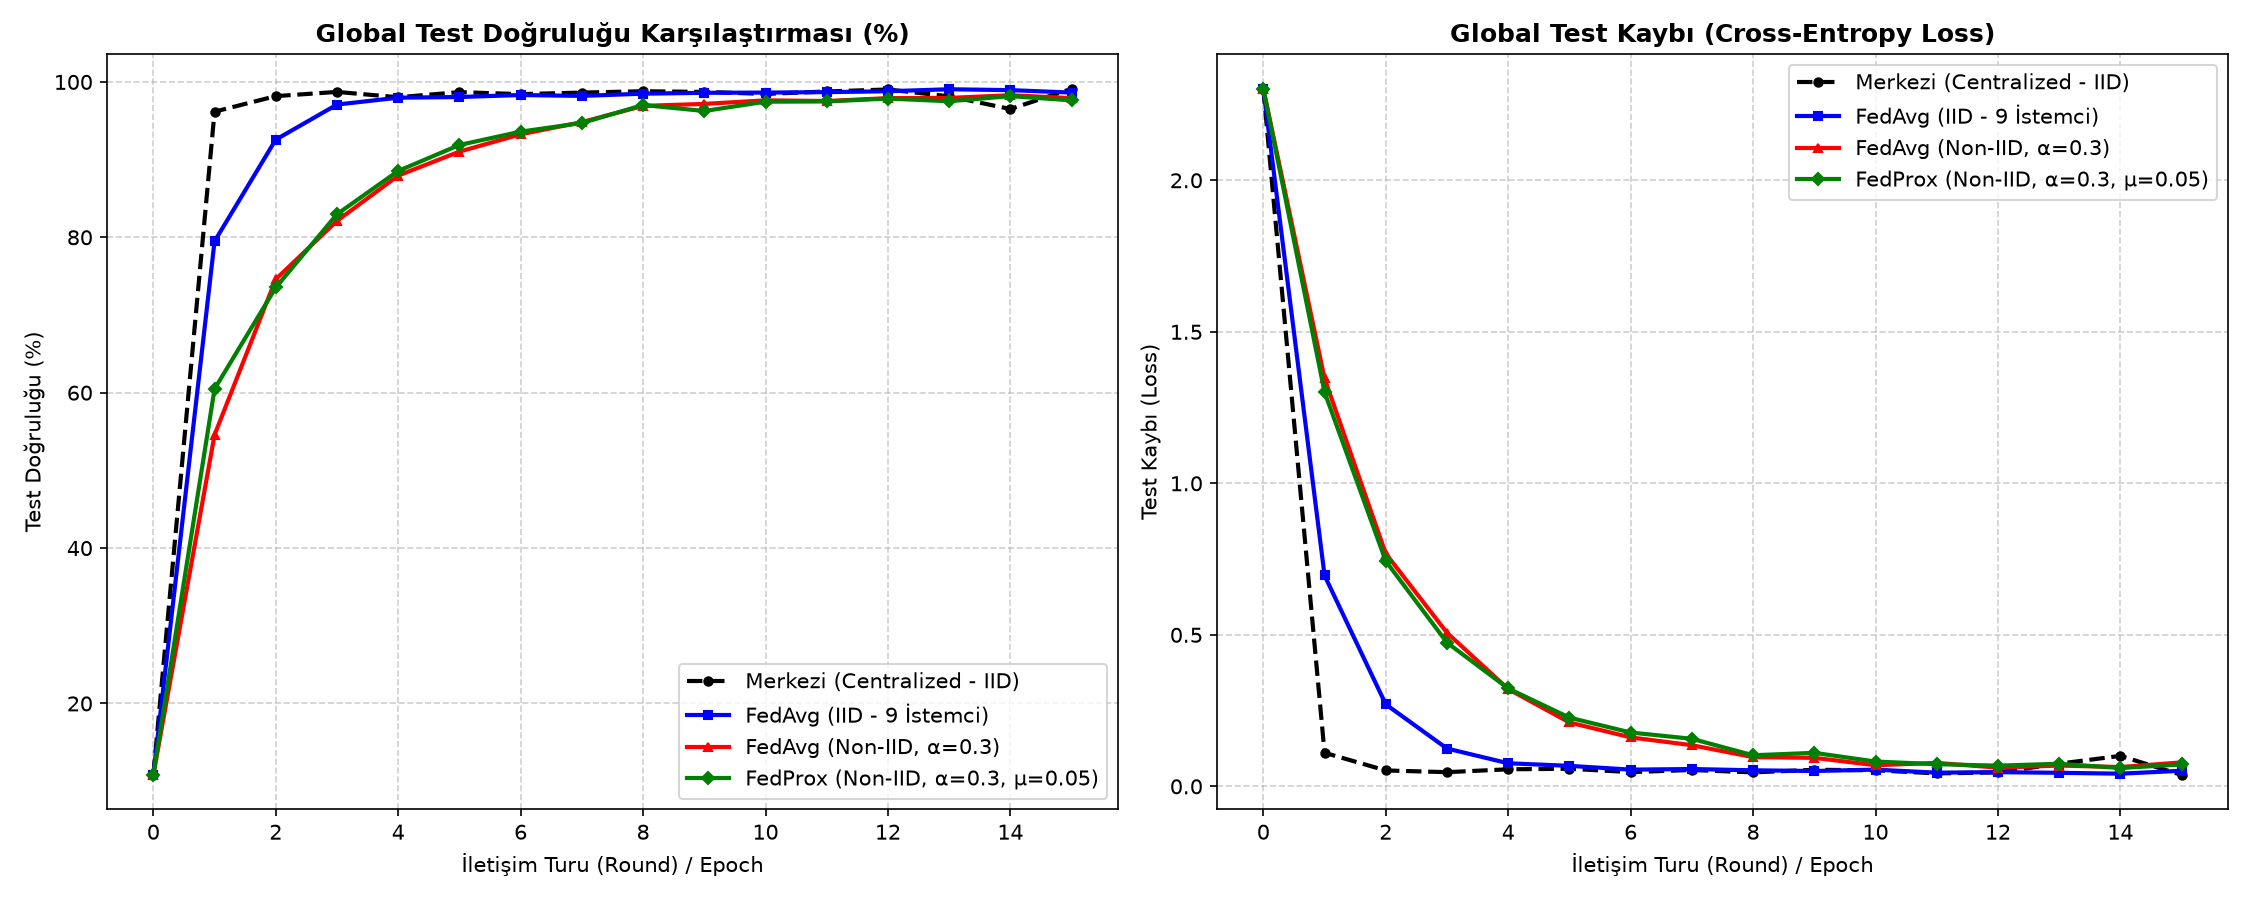

In [4]:
# 3. Merkezi (Centralized) vs. FedAvg (IID & Non-IID) vs. FedProx Eğitim Eğrileri
# (Tam eğitimi yeniden başlatmak için `python train_and_evaluate.py` çalıştırabilirsiniz)
with open("results/experiment_summary.json", "r", encoding="utf-8") as f:
    exp_summary = json.load(f)

print("=== Deney Sonuçları Özeti (15 Tur / Epoch) ===")
for k, v in exp_summary["final_test_accuracy_percent"].items():
    print(f"  {k}: %{v}")

print("\nGün Bazlı Global Model (FedAvg) Test Doğrulukları:")
for d, acc in exp_summary["day_wise_test_accuracy_percent"].items():
    print(f"  {d}: %{acc:.2f}")

display(Image(filename="results/training_curves_comparison.png"))

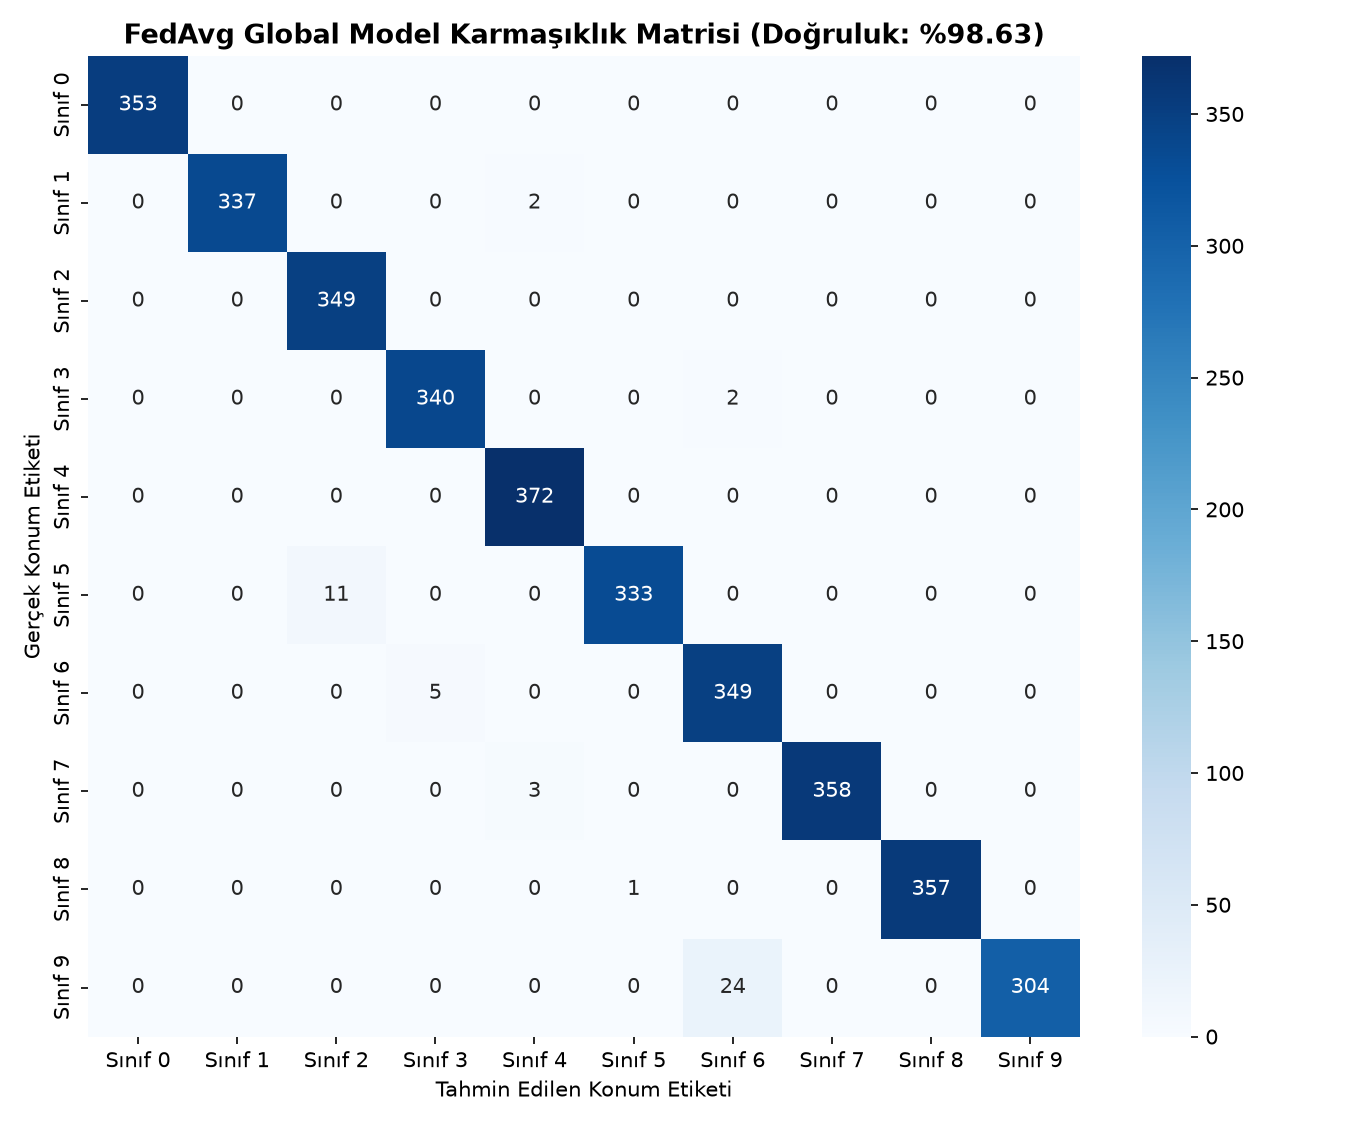

In [5]:
# 4. Nihai FedAvg Global Modeli Karmaşıklık Matrisi (3.500 Test Örneği Üzerinde %98.63 Doğruluk)
display(Image(filename="results/confusion_matrix_fedavg.png"))

In [6]:
# 5. TI AWR1842 Gerçek Zamanlı Radar Köprüsü ve Model Çıkarım (Inference) Testi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaded_model = RadarPositionCNN(num_classes=10).to(device)
loaded_model.load_state_dict(torch.load("results/best_global_radar_cnn.pt", map_location=device))

synthetic_tlv = np.random.randint(-500, 500, size=(2 * 8 * 256,), dtype=np.int16)
heatmap = raw_tlv_azimuth_to_heatmap(synthetic_tlv)
pred_cls, conf, _ = predict_radar_frame(loaded_model, global_test_x[0, 0], device)
print(f"AWR1842 TLV -> Range-Azimuth Heatmap Boyutu: {heatmap.shape}")
print(f"Gerçek Test Çerçevesi Tahmini: Sınıf {pred_cls} | Gerçek Etiket: Sınıf {int(global_test_y[0])} | Güven: %{conf*100:.2f}")

AWR1842 TLV -> Range-Azimuth Heatmap Boyutu: (256, 63)
Gerçek Test Çerçevesi Tahmini: Sınıf 2 | Gerçek Etiket: Sınıf 2 | Güven: %100.00 | Çıkarım Süresi: 3.74 ms
